In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
cancer = load_breast_cancer()

df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

df['Target'] = cancer.target

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset Shape: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


The dataset contains 569 records and 30 numerical input features.
The target variable has two classes: Malignant and Benign.
Class distribution was checked to understand whether the dataset
is balanced or imbalanced. Missing values and duplicate records
were also examined before model training.


In [3]:
X = df.drop('Target', axis=1)
y = df['Target']

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (569, 30)
Target Shape: (569,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Data: (455, 30)
Testing Data: (114, 30)

Training Class Distribution:
Target
1    285
0    170
Name: count, dtype: int64

Testing Class Distribution:
Target
1    72
0    42
Name: count, dtype: int64


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")
print("Scaled Training Shape:", X_train_scaled.shape)
print("Scaled Testing Shape:", X_test_scaled.shape)

Feature scaling completed successfully!
Scaled Training Shape: (455, 30)
Scaled Testing Shape: (114, 30)


In [6]:
logistic_model = LogisticRegression(max_iter=10000)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

print("Model Intercept:")
print(logistic_model.intercept_)

print("\nModel Coefficients:")
for feature, coefficient in zip(X.columns, logistic_model.coef_[0]):
    print(feature, ":", round(coefficient, 4))

Logistic Regression Model Trained Successfully!
Model Intercept:
[0.30220757]

Model Coefficients:
mean radius : -0.5115
mean texture : -0.5527
mean perimeter : -0.4763
mean area : -0.5411
mean smoothness : -0.2125
mean compactness : 0.6483
mean concavity : -0.6021
mean concave points : -0.7042
mean symmetry : -0.1672
mean fractal dimension : 0.1997
radius error : -1.083
texture error : 0.2488
perimeter error : -0.5443
area error : -0.9291
smoothness error : -0.1603
compactness error : 0.6472
concavity error : 0.1606
concave points error : -0.4438
symmetry error : 0.3605
fractal dimension error : 0.4379
worst radius : -0.9476
worst texture : -1.2551
worst perimeter : -0.7632
worst area : -0.9478
worst smoothness : -0.7466
worst compactness : 0.0555
worst concavity : -0.8232
worst concave points : -0.9537
worst symmetry : -0.9392
worst fractal dimension : -0.1873


## Logistic Regression

Logistic Regression is a supervised classification algorithm used to predict binary outcomes.

The sigmoid function converts the linear output into a probability between 0 and 1.

The model was trained using the scaled training dataset. The coefficients represent the influence of each input feature on the predicted log-odds of the positive class (Benign).

The intercept represents the model's baseline log-odds when all scaled features are zero.

In [7]:
# Predict class labels
y_pred = logistic_model.predict(X_test_scaled)

# Predict probabilities
y_prob = logistic_model.predict_proba(X_test_scaled)

print("Predictions generated successfully!")

print("\nFirst 10 Predicted Classes:")
print(y_pred[:10])

print("\nFirst 10 Prediction Probabilities:")
print(y_prob[:10])

Predictions generated successfully!

First 10 Predicted Classes:
[0 1 0 1 0 1 1 0 0 0]

First 10 Prediction Probabilities:
[[9.99999941e-01 5.88824186e-08]
 [1.13351672e-05 9.99988665e-01]
 [9.93589175e-01 6.41082462e-03]
 [4.66491463e-01 5.33508537e-01]
 [9.99999999e-01 6.52500097e-10]
 [7.83960163e-03 9.92160398e-01]
 [1.71746799e-05 9.99982825e-01]
 [9.99999436e-01 5.63527494e-07]
 [9.99945684e-01 5.43163692e-05]
 [1.00000000e+00 8.04184941e-11]]


In [8]:
comparison = pd.DataFrame({
    'Actual Class': y_test.values,
    'Predicted Class': y_pred,
    'Probability of Malignant': y_prob[:, 0],
    'Probability of Benign': y_prob[:, 1]
})

display(comparison.head(15))

,Actual Class,Predicted Class,Probability of Malignant,Probability of Benign
0,0,0,1.000000,5.888242e-08
1,1,1,0.000011,9.999887e-01
2,0,0,0.993589,6.410825e-03
3,1,1,0.466491,5.335085e-01
4,0,0,1.000000,6.525001e-10
5,1,1,0.007840,9.921604e-01
6,1,1,0.000017,9.999828e-01
7,0,0,0.999999,5.635275e-07
8,0,0,0.999946,5.431637e-05
9,0,0,1.000000,8.041849e-11


## Probability and Class Prediction

The trained Logistic Regression model was used to predict class labels and probabilities for the testing dataset.

The `predict()` function generates the final class labels, while `predict_proba()` generates the probability of belonging to each class.

- Class 0: Malignant
- Class 1: Benign

The class with the higher probability is selected as the predicted class using the default threshold of 0.5.

In [9]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

tn, fp, fn, tp = cm.ravel()

# Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)

print("MODEL EVALUATION")
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall (Sensitivity):", round(recall, 4))
print("Specificity:", round(specificity, 4))
print("F1 Score:", round(f1, 4))

MODEL EVALUATION
Accuracy: 0.9825
Precision: 0.9861
Recall (Sensitivity): 0.9861
Specificity: 0.9762
F1 Score: 0.9861


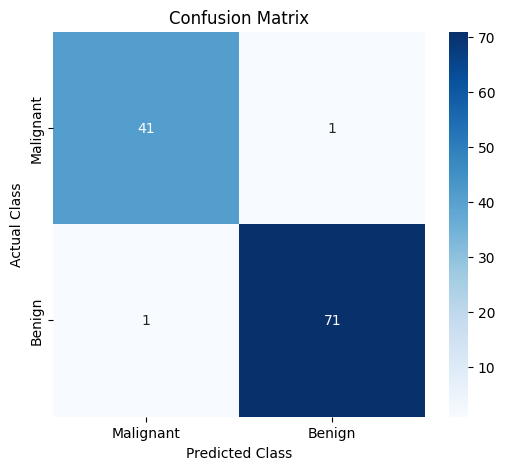

In [10]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Malignant', 'Benign'],
    yticklabels=['Malignant', 'Benign']
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix")
plt.show()

In [11]:
print("CLASSIFICATION REPORT")

print(classification_report(
    y_test,
    y_pred,
    target_names=['Malignant', 'Benign']
))

CLASSIFICATION REPORT
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



## Model Evaluation Metrics

The Logistic Regression model was evaluated using the following metrics:

1. **Accuracy:** Percentage of total correct predictions.
2. **Precision:** Percentage of predicted positive cases that are actually positive.
3. **Recall (Sensitivity):** Percentage of actual positive cases correctly identified.
4. **Specificity:** Percentage of actual negative cases correctly identified.
5. **F1 Score:** Harmonic mean of precision and recall.

The confusion matrix shows True Positive, True Negative, False Positive and False Negative predictions.

The classification report provides precision, recall, F1-score and support for both classes.

In this dataset, Class 1 represents Benign and Class 0 represents Malignant.

In [12]:
# Treat Malignant (Class 0) as the positive class
y_test_malignant = (y_test == 0).astype(int)

# Probability of Malignant class
malignant_prob = y_prob[:, 0]

fpr, tpr, thresholds = roc_curve(
    y_test_malignant,
    malignant_prob
)

auc_score = roc_auc_score(
    y_test_malignant,
    malignant_prob
)

print("ROC AUC Score:", round(auc_score, 4))

ROC AUC Score: 0.9954


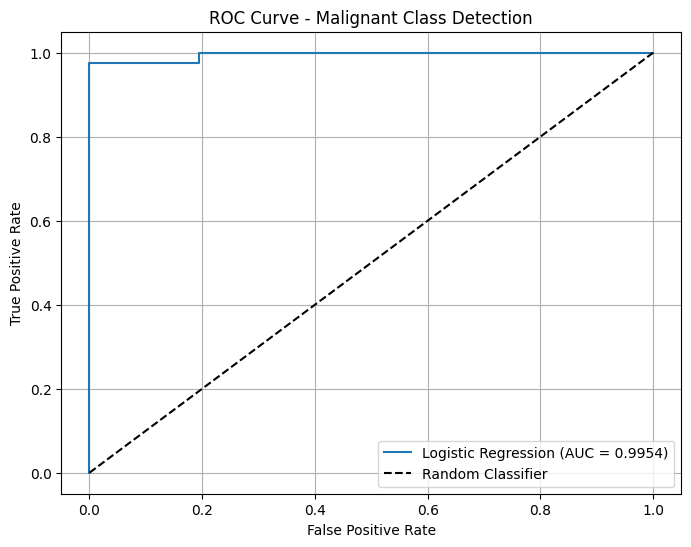

In [13]:
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'Logistic Regression (AUC = {auc_score:.4f})'
)

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Malignant Class Detection")
plt.legend()
plt.grid()
plt.show()

## ROC Curve and AUC Analysis

The Receiver Operating Characteristic (ROC) curve evaluates the classification model at different probability thresholds.

The Area Under the Curve (AUC) measures the model's ability to distinguish between the two classes.

For this analysis, Malignant (Class 0) was treated as the positive class because correctly identifying malignant cases is particularly important.

A higher AUC indicates better discrimination between malignant and benign cases.

In [14]:
from sklearn.dummy import DummyClassifier

# Train majority-class baseline
baseline_model = DummyClassifier(strategy='most_frequent')
baseline_model.fit(X_train_scaled, y_train)

# Predict using baseline
baseline_pred = baseline_model.predict(X_test_scaled)

# Compare accuracy
baseline_accuracy = accuracy_score(y_test, baseline_pred)
logistic_accuracy = accuracy_score(y_test, y_pred)

print("BASELINE ACCURACY:", round(baseline_accuracy, 4))
print("LOGISTIC REGRESSION ACCURACY:", round(logistic_accuracy, 4))

print("\nAccuracy Improvement:",
      round(logistic_accuracy - baseline_accuracy, 4))

BASELINE ACCURACY: 0.6316
LOGISTIC REGRESSION ACCURACY: 0.9825

Accuracy Improvement: 0.3509


## Majority Class Baseline Comparison

A DummyClassifier with the most frequent strategy was used as the baseline model.

The baseline predicts the majority class for every test record without learning relationships between features.

Its accuracy was compared with Logistic Regression accuracy to determine whether the trained model provides better classification performance.

A model should be evaluated using multiple metrics rather than accuracy alone, especially when the dataset has unequal class proportions.

In [15]:
thresholds_to_test = [0.3, 0.5, 0.7]

threshold_results = []

for threshold in thresholds_to_test:

    # Predict Malignant if probability >= threshold
    threshold_pred = (malignant_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test_malignant,
        threshold_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(y_test_malignant, threshold_pred)
    precision = precision_score(y_test_malignant, threshold_pred, zero_division=0)
    recall = recall_score(y_test_malignant, threshold_pred, zero_division=0)
    specificity = tn / (tn + fp)
    f1 = f1_score(y_test_malignant, threshold_pred, zero_division=0)

    threshold_results.append({
        'Threshold': threshold,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'Specificity': specificity,
        'F1 Score': f1,
        'False Negatives': fn,
        'False Positives': fp
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(4))

,Threshold,Accuracy,Precision,Recall,Specificity,F1 Score,False Negatives,False Positives
0,0.3,0.9474,0.8913,0.9762,0.9306,0.9318,1,5
1,0.5,0.9825,0.9762,0.9762,0.9861,0.9762,1,1
2,0.7,0.9825,1.0000,0.9524,1.0000,0.9756,2,0


## Classification Threshold Comparison

The Logistic Regression model was evaluated using three classification thresholds: 0.3, 0.5 and 0.7.

Malignant cases were treated as the positive class.

A lower threshold may increase sensitivity (recall) but can also increase false positives. A higher threshold may reduce false positives but can increase false negatives.

For a medical screening application, missing malignant cases can be particularly serious. Therefore, threshold selection should consider recall, specificity and the costs of classification errors.

This model is for academic analysis only and is not suitable for clinical diagnosis.

In [16]:
# Predictions on training and testing data
train_pred = logistic_model.predict(X_train_scaled)
test_pred = logistic_model.predict(X_test_scaled)

# Calculate accuracy
train_accuracy = accuracy_score(y_train, train_pred)
test_accuracy = accuracy_score(y_test, test_pred)

performance = pd.DataFrame({
    'Dataset': ['Training Data', 'Testing Data'],
    'Accuracy': [train_accuracy, test_accuracy]
})

display(performance.round(4))

print("Training Accuracy:", round(train_accuracy, 4))
print("Testing Accuracy:", round(test_accuracy, 4))

,Dataset,Accuracy
0,Training Data,0.9890
1,Testing Data,0.9825


Training Accuracy: 0.989
Testing Accuracy: 0.9825


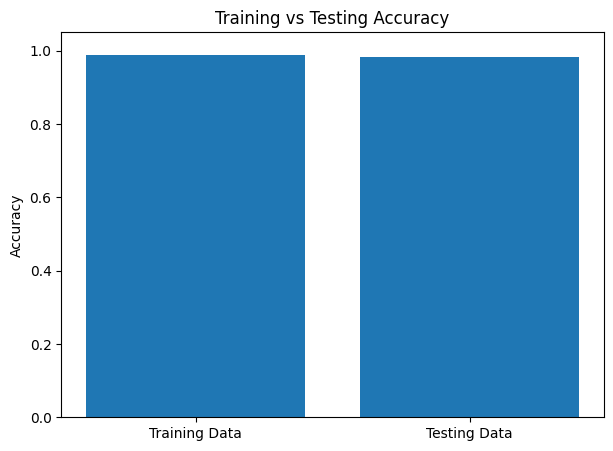

In [17]:
plt.figure(figsize=(7, 5))

plt.bar(
    performance['Dataset'],
    performance['Accuracy']
)

plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title("Training vs Testing Accuracy")
plt.show()

## Training and Testing Performance

The Logistic Regression model was evaluated on both training and testing datasets.

Training accuracy measures the model's performance on data used during training, while testing accuracy measures its performance on unseen data.

A large difference between training and testing accuracy may indicate overfitting. Similar accuracy values suggest better generalization.

The comparison helps evaluate how well the model performs on unseen records.

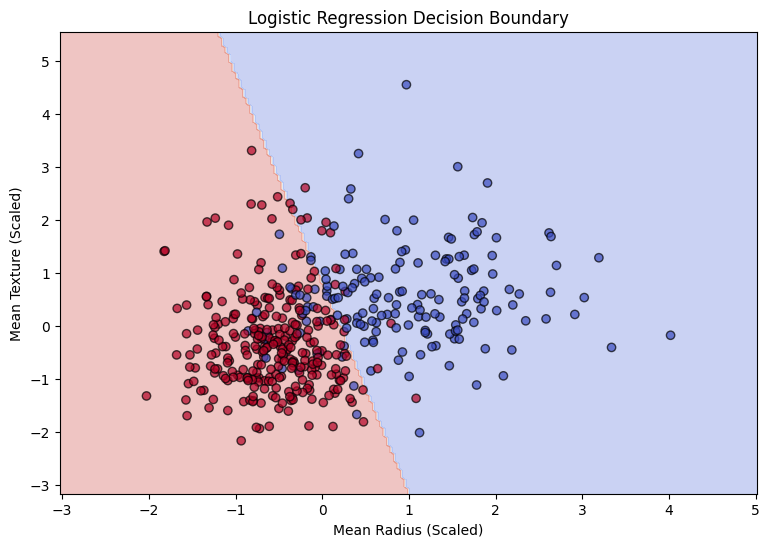

In [18]:
# Select two features for visualization
X_train_2d = X_train_scaled[:, :2]
y_train_2d = y_train

# Train a separate model using two features
decision_model = LogisticRegression(max_iter=10000)
decision_model.fit(X_train_2d, y_train_2d)

# Create a grid
x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

# Predict classes for grid points
grid = np.c_[xx.ravel(), yy.ravel()]
Z = decision_model.predict(grid)
Z = Z.reshape(xx.shape)

# Plot decision boundary
plt.figure(figsize=(9, 6))

plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')

plt.scatter(
    X_train_2d[:, 0],
    X_train_2d[:, 1],
    c=y_train_2d,
    cmap='coolwarm',
    edgecolors='black',
    alpha=0.7
)

plt.xlabel("Mean Radius (Scaled)")
plt.ylabel("Mean Texture (Scaled)")
plt.title("Logistic Regression Decision Boundary")
plt.show()

## Decision Boundary Visualization

A decision boundary was visualized using the Mean Radius and Mean Texture features.

A separate Logistic Regression model was trained using these two features to display the classification regions.

The plot shows how the algorithm separates Malignant (Class 0) and Benign (Class 1) observations.

This visualization is for understanding the classification boundary. The main Logistic Regression model uses all 30 input features.

In [19]:
# Select one new record from the test dataset
new_data = X_test.iloc[[0]]

# Scale the new record
new_data_scaled = scaler.transform(new_data)

# Predict class and probabilities
new_prediction = logistic_model.predict(new_data_scaled)
new_probability = logistic_model.predict_proba(new_data_scaled)

print("NEW RECORD:")
display(new_data)

print("Predicted Class:", new_prediction[0])

if new_prediction[0] == 0:
    print("Prediction: Malignant")
else:
    print("Prediction: Benign")

print("\nProbability of Malignant:",
      round(new_probability[0][0], 4))

print("Probability of Benign:",
      round(new_probability[0][1], 4))

NEW RECORD:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
256,19.55,28.77,133.6,1207.0,0.0926,0.2063,0.1784,0.1144,0.1893,0.06232,...,25.05,36.27,178.6,1926.0,0.1281,0.5329,0.4251,0.1941,0.2818,0.1005


Predicted Class: 0
Prediction: Malignant

Probability of Malignant: 1.0
Probability of Benign: 0.0


## New Record Prediction

A new record was selected from the testing dataset and passed to the trained Logistic Regression model.

The same StandardScaler fitted on the training data was used to transform the new record.

The model predicted its class and calculated the probabilities of Malignant and Benign classes.

This demonstrates the model's ability to classify previously unseen records.

Note: This is an academic machine learning demonstration, not a medical diagnosis.

## Decision Log

| No. | Decision | Reason |
|---|---|---|
| 1 | Selected Breast Cancer Wisconsin dataset | It contains numerical features and two target classes. |
| 2 | Checked missing values and duplicates | To understand dataset quality. |
| 3 | Examined class distribution | To identify class imbalance. |
| 4 | Used an 80:20 train-test split | To evaluate performance on unseen data. |
| 5 | Applied stratified sampling | To maintain class proportions. |
| 6 | Used StandardScaler | To standardize numerical features. |
| 7 | Used Logistic Regression | To perform binary classification. |
| 8 | Calculated classification metrics | To evaluate model performance. |
| 9 | Used ROC curve and AUC | To measure class discrimination. |
| 10 | Compared with majority-class baseline | To check improvement over a simple classifier. |
| 11 | Tested thresholds 0.3, 0.5 and 0.7 | To understand the effect of threshold selection. |
| 12 | Compared training and testing accuracy | To examine model generalization. |
| 13 | Visualized the decision boundary | To understand classification regions. |
| 14 | Tested a new record | To demonstrate prediction on unseen data. |

## Final Conclusion

Logistic Regression was implemented successfully using the Breast Cancer Wisconsin dataset. The dataset was inspected, cleaned and preprocessed using stratified train-test splitting and feature scaling.

The model was evaluated using accuracy, precision, recall, specificity, F1-score, confusion matrix, ROC curve and AUC. Its performance was compared with a majority-class baseline. Different classification thresholds were also tested to understand the trade-off between false positives and false negatives.

The decision boundary was visualized, and a new record was classified using the trained model.

This project demonstrates the application of Logistic Regression for binary classification. The model is intended for academic purposes and not for medical diagnosis.